# L1.1 - obraz jako tablica liczb

Sieć neuronowa nie widzi „zdjęcia” - dostaje tablicę liczb o określonym **kształcie**, **typie** i **zakresie wartości**.

Plan:
1. Wczytywanie obrazu trzema bibliotekami i pułapki z tym związane
2. Kształt i układ kanałów (`HWC` a `CHW`)
3. Typ danych i zakres wartości
4. Histogram, normalizacja i standaryzacja
5. Przekształcenia geometryczne
6. Przekształcenia radiometryczne
7. Konwolucja - pomost do sieci CNN

In [1]:
import warnings
import numpy as np
import cv2
import matplotlib.pyplot as plt
import rasterio
import torch
from PIL import Image
from pathlib import Path

warnings.filterwarnings("ignore", category=rasterio.errors.NotGeoreferencedWarning)
DANE = Path("dane")

Matplotlib is building the font cache; this may take a moment.


In [2]:
def pokaz(obrazy, tytuly=None, rozmiar=4, cmap="gray"):
    # Wyświetla jeden obraz lub listę obrazów obok siebie.
    if not isinstance(obrazy, (list, tuple)):
        obrazy = [obrazy]
    fig, axes = plt.subplots(1, len(obrazy), figsize=(rozmiar * len(obrazy), rozmiar), squeeze=False)
    for i, (ax, im) in enumerate(zip(axes[0], obrazy)):
        ax.imshow(im, cmap=cmap if im.ndim == 2 else None)
        if tytuly:
            ax.set_title(tytuly[i], fontsize=10)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

## 1. Wczytywanie obrazu

Ten sam plik wczytany trzema bibliotekami daje trzy różne tablice:

| Biblioteka | Układ | Kolejność kanałów | Kiedy używać |
| --- | --- | --- | --- |
| OpenCV `cv2.imread` | (H, W, C) | **BGR** | szybkie przetwarzanie, filtry |
| Pillow `Image.open` | (H, W, C) | RGB | torchvision korzysta z niej domyślnie |
| rasterio | **(C, H, W)** | jak w pliku | dane przestrzenne: GeoTIFF, wiele kanałów, 16 bitów, georeferencja |

In [3]:
sciezka = DANE / "lot1.tif"

img_cv = cv2.imread(str(sciezka))                 # OpenCV
img_pil = np.array(Image.open(sciezka))           # Pillow
with rasterio.open(sciezka) as src:               # rasterio
    img_rio = src.read()
    profil = src.profile

for nazwa, tab in [("OpenCV", img_cv), ("Pillow", img_pil), ("rasterio", img_rio)]:
    print(f"{nazwa:9s} kształt={tab.shape}  typ={tab.dtype}  min={tab.min()}  max={tab.max()}")

OpenCV    kształt=(625, 876, 3)  typ=uint8  min=0  max=255
Pillow    kształt=(625, 876, 3)  typ=uint8  min=0  max=255
rasterio  kształt=(3, 625, 876)  typ=uint8  min=0  max=255


In [4]:
# Profil rastra: liczba kanałów, typ, układ współrzędnych, transformacja piksel -> współrzędne
profil

{'driver': 'GTiff', 'dtype': 'uint8', 'nodata': None, 'width': 876, 'height': 625, 'count': 3, 'crs': CRS.from_wkt('GEOGCS["WGS 84",DATUM["World Geodetic System 1984",SPHEROID["WGS 84",6378137,298.257223563]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Latitude",NORTH],AXIS["Longitude",EAST]]'), 'transform': Affine(1.0, 0.0, 0.0,
       0.0, -1.0, 0.0), 'blockxsize': 876, 'blockysize': 3, 'tiled': False, 'interleave': 'pixel'}

### Pułapka 1: BGR zamiast RGB

`matplotlib` zakłada RGB. Obraz z OpenCV wyświetlony bez konwersji ma zamienione kanały czerwony i niebieski. Sieć wytrenowana na RGB, której podamy BGR, będzie działać wyraźnie gorzej - i nie zgłosi żadnego błędu.

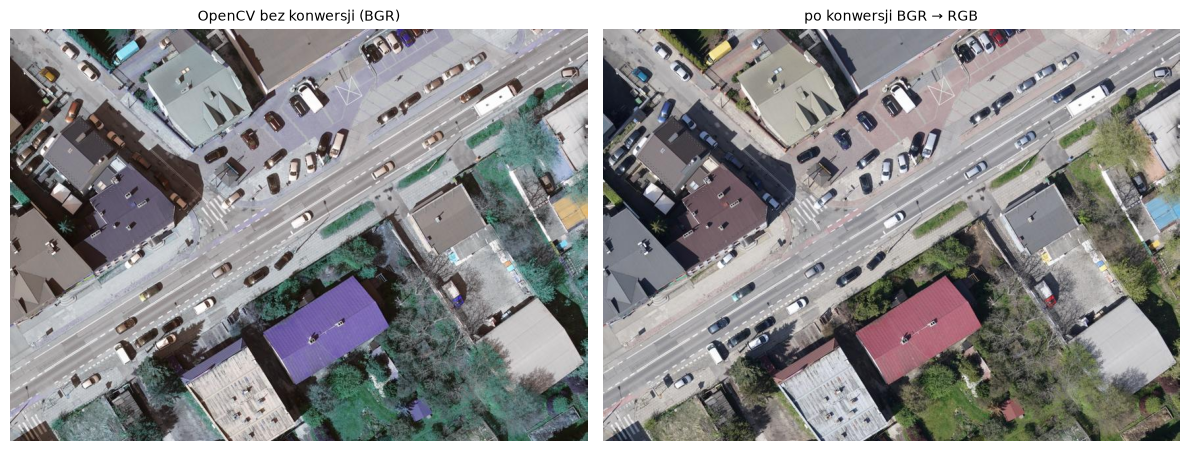

In [5]:
img = cv2.cvtColor(img_cv, cv2.COLOR_BGR2RGB)
pokaz([img_cv, img], ["OpenCV bez konwersji (BGR)", "po konwersji BGR → RGB"], rozmiar=6)

### Pułapka 2: układ osi

rasterio zwraca `(C, H, W)`, czyli kanały na początku. Tak samo oczekuje PyTorch. `matplotlib`, OpenCV i albumentations oczekują `(H, W, C)`.

In [6]:
hwc = np.transpose(img_rio, (1, 2, 0))        # (C,H,W) -> (H,W,C)
print("rasterio:", img_rio.shape, "-> po transpozycji:", hwc.shape)
print("Czy identyczny z Pillow?", np.array_equal(hwc, img_pil))

tensor = torch.from_numpy(img).permute(2, 0, 1)   # (H,W,C) -> (C,H,W) dla PyTorch
print("Tensor PyTorch:", tensor.shape, tensor.dtype)

rasterio: (3, 625, 876) -> po transpozycji: (625, 876, 3)
Czy identyczny z Pillow? True
Tensor PyTorch: torch.Size([3, 625, 876]) torch.uint8


### Pułapka 3: kanał alfa

Pliki PNG często mają czwarty kanał (przezroczystość). Sieć oczekująca 3 kanałów zgłosi błąd wymiarów.

**Zadanie 1.** Wczytaj `dane/Engels.png` biblioteką Pillow tak, aby otrzymać tablicę RGB o 3 kanałach. Wypisz kształt przed i po.

Tryb: RGBA | kształt: (978, 1426, 4)
Po konwersji: (978, 1426, 3)


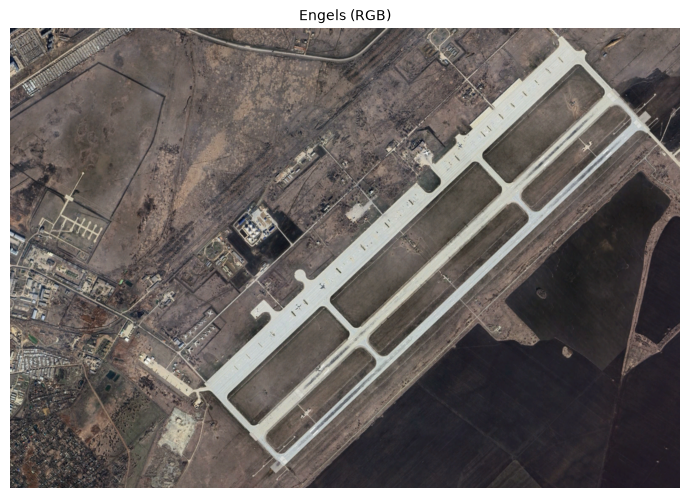

In [ ]:
engels_pil = Image.open(DANE / "Engels.png")
print("Tryb:", engels_pil.mode, "| kształt:", np.array(engels_pil).shape)

#Redukcja do RGB bez alfa
engels = np.array(engels_pil.convert("RGB"))
print("Po konwersji:", engels.shape)
pokaz(engels, ["Engels (RGB)"], rozmiar=7)

## 2. Kanały

Obraz RGB to trzy tablice 2D. Na zdjęciach lotniczych roślinność jest zwykle najjaśniejsza w kanale zielonym, a cienie ciemne we wszystkich.

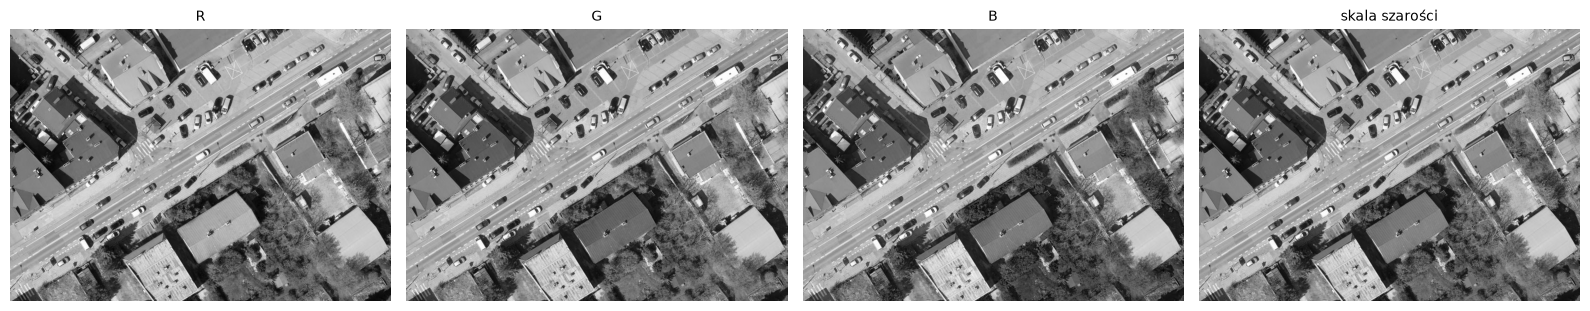

In [8]:
R, G, B = img[:, :, 0], img[:, :, 1], img[:, :, 2]
szary = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)     # 0.299 R + 0.587 G + 0.114 B
pokaz([R, G, B, szary], ["R", "G", "B", "skala szarości"])

## 3. Typ danych i zakres wartości

Obrazy 8-bitowe mają typ `uint8` (0–255). Arytmetyka na `uint8` **zawija się** bez ostrzeżenia.

In [9]:
a = np.array([200, 250], dtype=np.uint8)
print("uint8:  200 + 100 =", (a + 100)[0], "  (zawinięcie modulo 256)")
print("poprawnie:", np.clip(a.astype(np.int16) + 100, 0, 255).astype(np.uint8))

uint8:  200 + 100 = 44   (zawinięcie modulo 256)
poprawnie: [255 255]


Do sieci podajemy liczby zmiennoprzecinkowe `float32`. Trzy typowe reprezentacje:

| Reprezentacja | Zakres | Jak uzyskać |
| --- | --- | --- |
| surowa | 0–255, `uint8` | wczytanie pliku |
| znormalizowana | 0–1, `float32` | `img / 255` |
| standaryzowana | średnia ≈ 0, odch. ≈ 1 | `(x - mean) / std` dla każdego kanału |

Uwaga na `plt.imshow`: dla `float` oczekuje zakresu 0–1, dla `uint8` 0–255. Tablica `float` o wartościach 0–255 wyświetli się jako biały prostokąt.

In [10]:
img_f = img.astype(np.float32) / 255.0
print("float:", img_f.dtype, img_f.min(), img_f.max())

float: float32 0.0 1.0


## 4. Histogram, statystyki i standaryzacja

Standaryzacja wymaga średniej i odchylenia standardowego **każdego kanału**. W L4 użyjemy gotowych statystyk ImageNet; dla własnych danych (np. SAR w projekcie) trzeba je policzyć samodzielnie - i tylko na zbiorze treningowym.

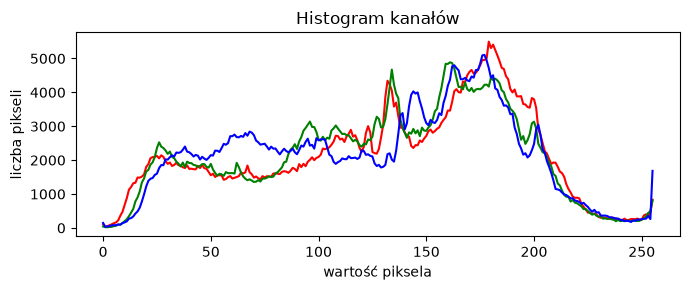

In [11]:
plt.figure(figsize=(7, 3))
for i, kolor in enumerate(["r", "g", "b"]):
    hist, _ = np.histogram(img[:, :, i], bins=256, range=(0, 256))
    plt.plot(hist, color=kolor)
plt.xlabel("wartość piksela"); plt.ylabel("liczba pikseli"); plt.title("Histogram kanałów")
plt.tight_layout(); plt.show()

**Zadanie 2.** Oblicz średnią i odchylenie standardowe każdego kanału obrazu `img_f` (wynik: dwa wektory po 3 liczby). Następnie wykonaj standaryzację i sprawdź, że po niej średnie są bliskie 0, a odchylenia bliskie 1.

In [12]:
srednia = img_f.mean(axis=(0, 1))
odchylenie = img_f.std(axis=(0, 1))
print("mean:", srednia.round(4))
print("std: ", odchylenie.round(4))

img_std = (img_f - srednia) / odchylenie
print("po standaryzacji -> mean:", img_std.mean(axis=(0, 1)).round(4), " std:", img_std.std(axis=(0, 1)).round(4))

mean: [0.5219 0.5096 0.5014]
std:  [0.2285 0.2194 0.224 ]
po standaryzacji -> mean: [-0.0001 -0.0003 -0.0004]  std: [1.     0.9999 1.0002]


### Rozciąganie percentylowe

Dane satelitarne i lotnicze 12/16-bitowe wykorzystują zwykle niewielką część zakresu. Zamiast dzielić przez maksimum (wrażliwe na pojedyncze odblaski), rozciągamy między 2. a 98. percentylem.

**Zadanie 3.** Uzupełnij funkcję `rozciagnij`.

zakres: 300 - 3360 uint16


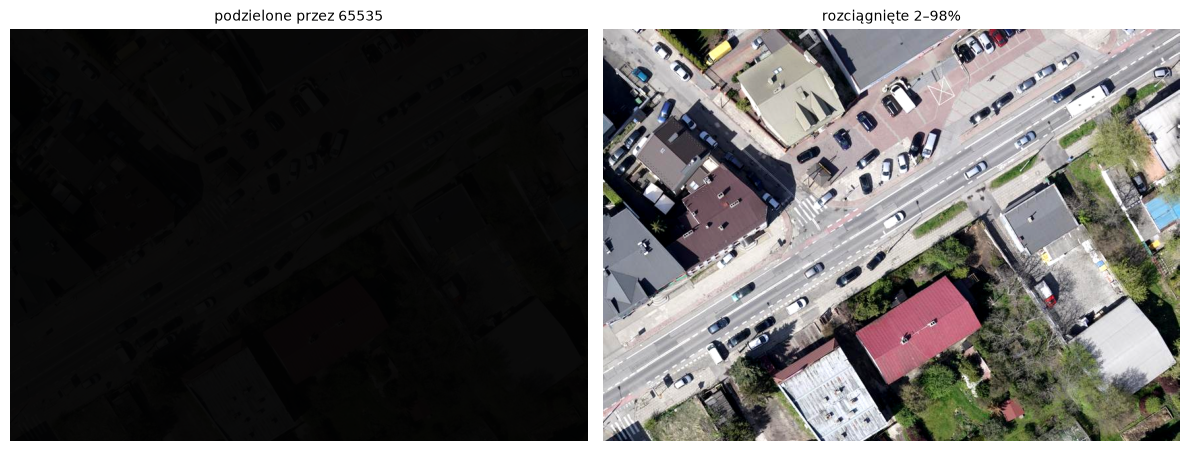

In [17]:
def rozciagnij(obraz, p_min=2, p_max=98):
    # Liniowe rozciągnięcie wartości między percentylami do zakresu 0-1.
    obraz = obraz.astype(np.float32)
    lo, hi = np.percentile(obraz, (p_min, p_max))
    wynik = np.clip((obraz - lo) / (hi - lo), 0, 1)
    return wynik

# symulacja danych 16-bitowych o małym kontraście
ciemny16 = (img.astype(np.uint16) * 12 + 300)
print("zakres:", ciemny16.min(), "-", ciemny16.max(), ciemny16.dtype)
pokaz([ciemny16 / 65535, rozciagnij(ciemny16)], ["podzielone przez 65535", "rozciągnięte 2–98%"], rozmiar=6)

## 5. Przekształcenia geometryczne

Te same operacje posłużą za chwilę do **cięcia kafli** i **augmentacji**.

### Zmiana rozmiaru i interpolacja


Interpolacja liniowa i sześcienna tworzą **wartości pośrednie**. Dla jasności pikseli to pożądane, dla numerów klas nie: między klasą 0 a klasą 5 pojawiłyby się klasy 1-4, których w tym miejscu nie ma. Dlatego obrazy skalujemy z interpolacją, a **maski klas wyłącznie metodą najbliższego sąsiada**. Przykład zobaczymy w L1.2.

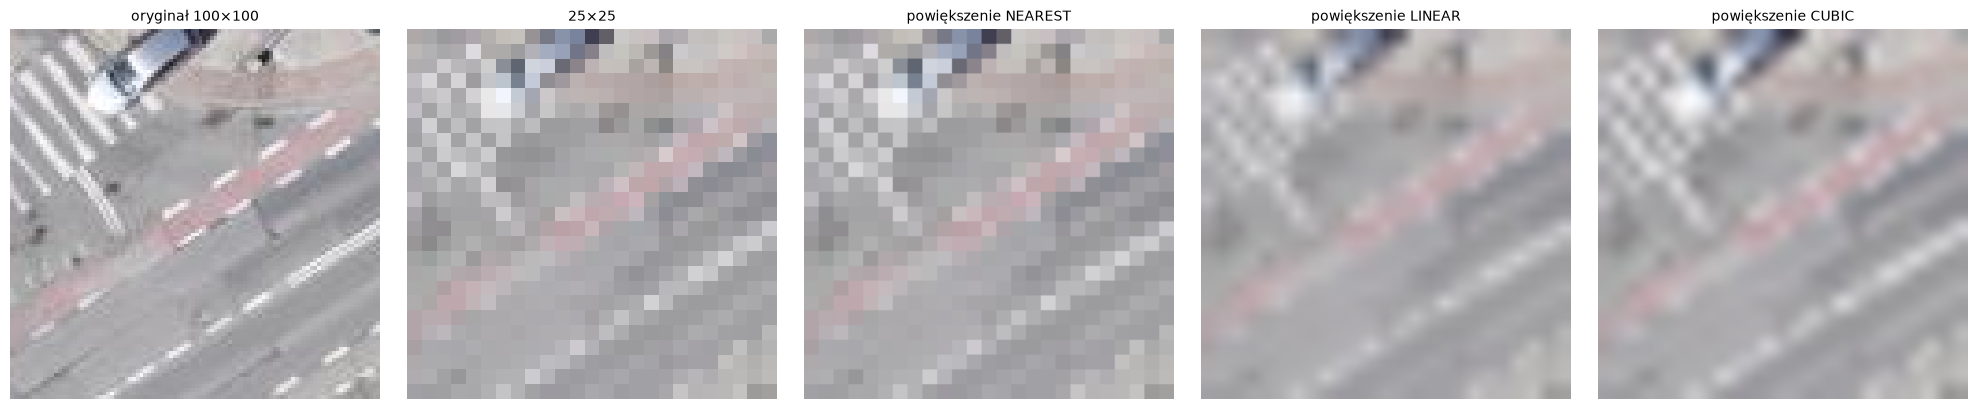

In [21]:
wycinek = img[250:350, 300:400]
maly = cv2.resize(wycinek, (25, 25), interpolation=cv2.INTER_AREA)       # pomniejszanie: INTER_AREA
metody = {"NEAREST": cv2.INTER_NEAREST, "LINEAR": cv2.INTER_LINEAR, "CUBIC": cv2.INTER_CUBIC}
powiekszone = [cv2.resize(maly, (200, 200), interpolation=m) for m in metody.values()]
pokaz([wycinek, maly] + powiekszone, ["oryginał 100×100", "25×25"] + [f"powiększenie {n}" for n in metody])

### Odbicia, obroty, wycinanie

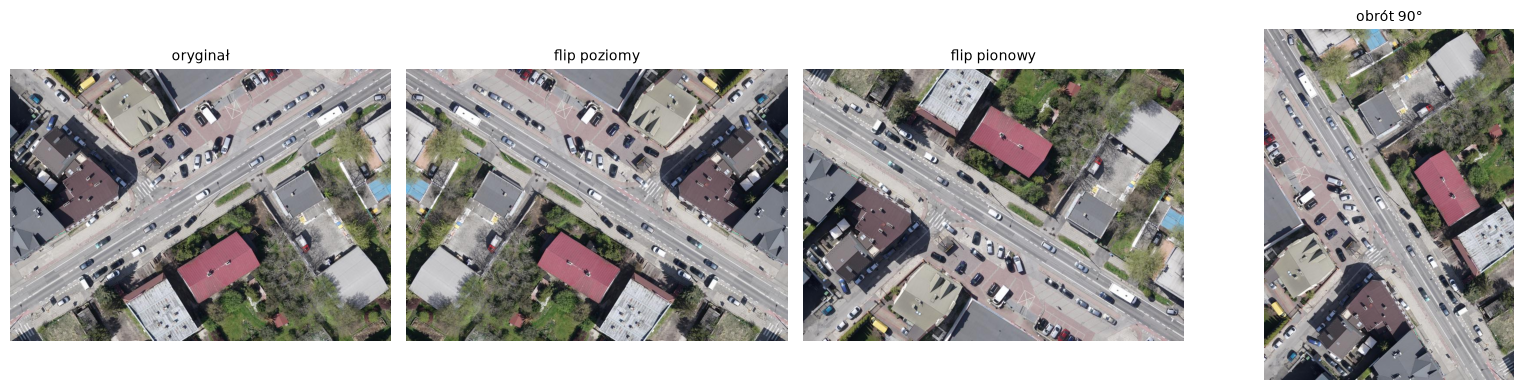

In [22]:
poziomo = cv2.flip(img, 1)                 # odbicie względem osi pionowej (lewo-prawo)
pionowo = cv2.flip(img, 0)                 # góra-dół
obrot90 = np.rot90(img, k=1)               # obrót o 90° bez interpolacji i bez pustych rogów
pokaz([img, poziomo, pionowo, obrot90], ["oryginał", "flip poziomy", "flip pionowy", "obrót 90°"])

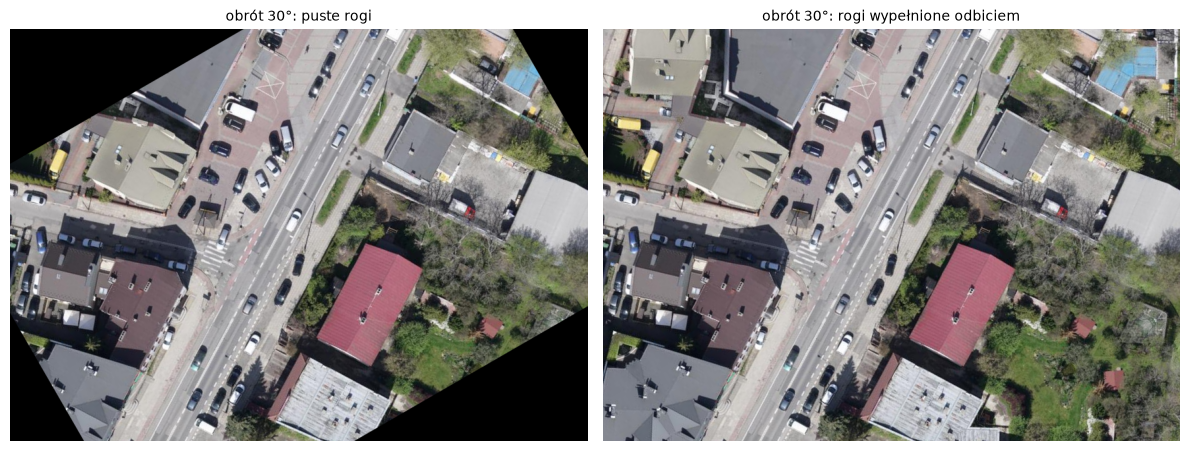

In [23]:
# Obrót o dowolny kąt wymaga interpolacji i zostawia puste rogi
h, w = img.shape[:2]
M = cv2.getRotationMatrix2D((w / 2, h / 2), 30, 1.0)       # środek, kąt (przeciwnie do zegara), skala
czarne = cv2.warpAffine(img, M, (w, h))
odbite = cv2.warpAffine(img, M, (w, h), borderMode=cv2.BORDER_REFLECT_101)
pokaz([czarne, odbite], ["obrót 30°: puste rogi", "obrót 30°: rogi wypełnione odbiciem"], rozmiar=6)

**Zadanie 4.** Napisz funkcję `losowy_wycinek(obraz, rozmiar, rng)`, która zwraca losowy kwadratowy fragment obrazu o boku `rozmiar`. To najprostsza augmentacja (*random crop*) i jednocześnie najprostszy sposób pobierania próbek z dużego rastra.

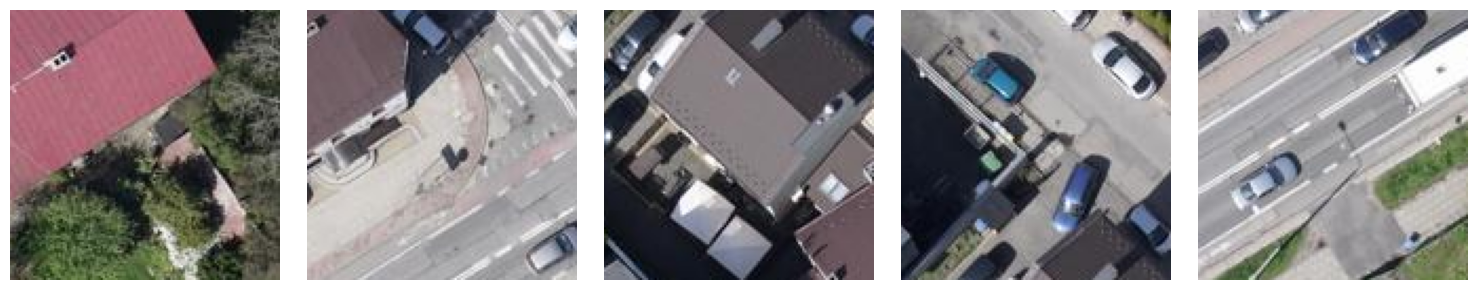

In [49]:
def losowy_wycinek(obraz, rozmiar, rng):
    h, w = obraz.shape[:2]
    y = rng.integers(0, h - rozmiar + 1)
    x = rng.integers(0, w - rozmiar + 1)
    return obraz[y:y + rozmiar, x:x + rozmiar]

rng = np.random.default_rng(0)
pokaz([losowy_wycinek(img, 128, rng) for _ in range(5)], rozmiar=3)

## 6. Przekształcenia radiometryczne

Zmieniają wartości pikseli, nie ich położenie. W augmentacji symulują inne oświetlenie, inną kamerę, mgłę czy gorszą ostrość.

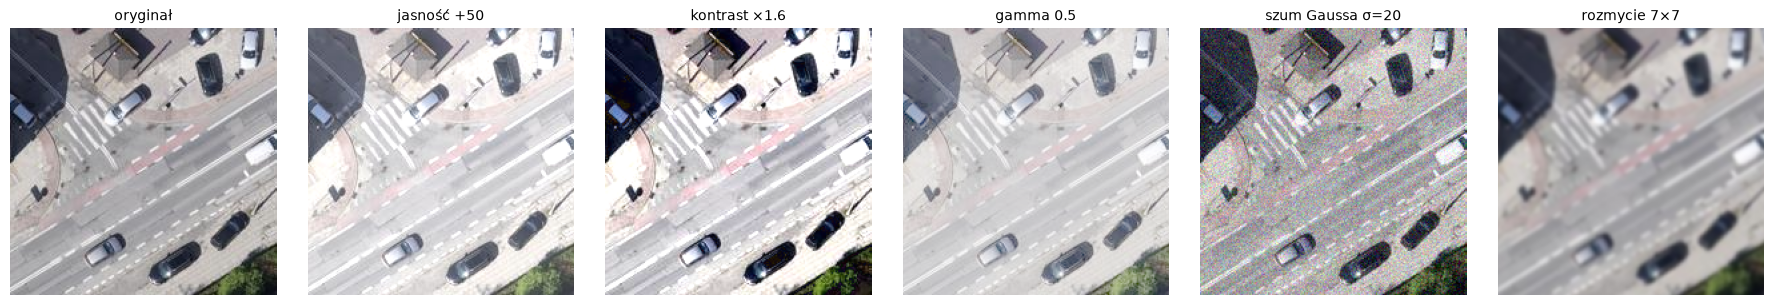

In [28]:
jasniej = cv2.convertScaleAbs(img, alpha=1.0, beta=50)          # wynik = alpha * x + beta (z przycięciem)
kontrast = cv2.convertScaleAbs(img, alpha=1.6, beta=-60)

gamma = 0.5                                                      # < 1 rozjaśnia cienie, > 1 przyciemnia
po_gamma = (255 * (img / 255.0) ** gamma).astype(np.uint8)

rng = np.random.default_rng(0)
szum = np.clip(img + rng.normal(0, 20, img.shape), 0, 255).astype(np.uint8)
rozmycie = cv2.GaussianBlur(img, (7, 7), 0)

w = img[200:400, 250:450]
s = (slice(200, 400), slice(250, 450))
pokaz([w, jasniej[s], kontrast[s], po_gamma[s], szum[s], rozmycie[s]],
      ["oryginał", "jasność +50", "kontrast ×1.6", "gamma 0.5", "szum Gaussa σ=20", "rozmycie 7×7"], rozmiar=3)

## 7. Konwolucja - pomost do CNN

Filtr (kernel) to mała tablica wag przesuwana po obrazie; nowa wartość piksela to suma ważona sąsiedztwa. W CPO wagi dobieraliśmy ręcznie (Sobel, Gauss). **Sieć konwolucyjna wykonuje dokładnie tę samą operację, ale wagi kerneli wyznacza w trakcie uczenia.**

Zgodność wyników (poza brzegiem): True


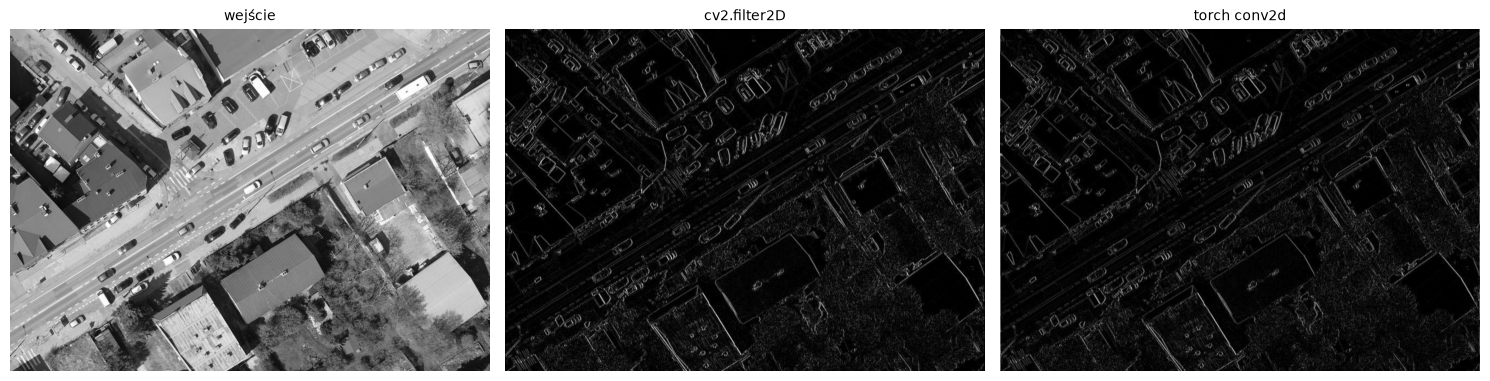

In [25]:
sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]], dtype=np.float32)

szary_f = szary.astype(np.float32)
krawedzie_cv = cv2.filter2D(szary_f, -1, sobel_x)

# To samo w PyTorch: warstwa konwolucyjna z ręcznie ustawionym kernelem
wejscie = torch.from_numpy(szary_f)[None, None]                 # (1, 1, H, W)
kernel = torch.from_numpy(sobel_x)[None, None]                  # (1, 1, 3, 3)
krawedzie_pt = torch.nn.functional.conv2d(wejscie, kernel, padding=1)[0, 0].numpy()

print("Zgodność wyników (poza brzegiem):", np.allclose(krawedzie_cv[1:-1, 1:-1], krawedzie_pt[1:-1, 1:-1]))
pokaz([szary, np.abs(krawedzie_cv), np.abs(krawedzie_pt)], ["wejście", "cv2.filter2D", "torch conv2d"], rozmiar=5)

**Zadanie 5.** Zdefiniuj kernel wyostrzający 3×3 (suma wag = 1, środek dodatni, sąsiedzi ujemni) i zastosuj go do obrazu `img`. Porównaj wycinek przed i po.

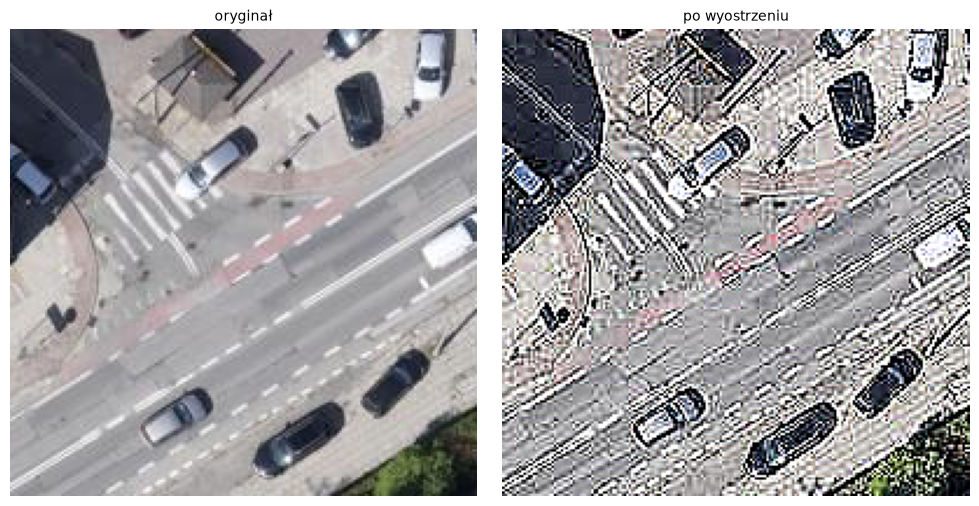

In [33]:
ostrzacy = np.array([[0, -3, 0],
                     [-3, 13, -3],
                     [0, -3, 0]], dtype=np.float32)
wyostrzony = cv2.filter2D(img, -1, ostrzacy)
pokaz([img[s], wyostrzony[s]], ["oryginał", "po wyostrzeniu"], rozmiar=5)

## Podsumowanie

Przed podaniem obrazu do sieci zawsze sprawdź:

1. **kształt** - `(C, H, W)` dla PyTorch, liczba kanałów zgodna z modelem,
2. **kolejność kanałów** - RGB, nie BGR,
3. **typ i zakres** - `float32`, znormalizowany tymi samymi statystykami co dane treningowe,
4. **maski** - typ całkowity, skalowane wyłącznie metodą najbliższego sąsiada.